# Codificación de las etiquetas en clasificación

In [1]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
#LEEMOS LOS DATOS DEL IRIS DATASET
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

# El conjunto de datos Iris no tiene encabezado, agregaremos nombres a las columnas en español
nombres_columnas = ['longitud_sepalo', 'ancho_sepalo', 'longitud_petalo', 'ancho_petalo', 'clase']

# Leer desde la URL con pandas
data = pd.read_csv(url, names=nombres_columnas)

In [5]:
# Pasamos las etiquetas a numpy y visualizamos
y = data.clase.to_numpy()
y

array(['Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-versicolor', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-versicolor', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-versicolor', 'Iris-versic

In [14]:
# Codificación con Label Encoding (y={0,1,...}) Lo que hace esto es asignar un número entero a cada clase. Por ejemplo, si tenemos tres clases 'setosa', 'versicolor' y 'virginica', LabelEncoder las codificará como 0, 1 y 2 respectivamente.
label_encoder = LabelEncoder()
y_labels = label_encoder.fit_transform(y)

#visualizamos
y_labels

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [11]:
# Codificación con One-Hot Encoding usando `sparse_output`
onehot_encoder = OneHotEncoder(sparse_output=False)
y_onehot = onehot_encoder.fit_transform(y.reshape(-1, 1))
y_onehot[0:10]

array([[1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.]])

In [12]:
# Vemos las dimensiones del array y_onehot:
y_onehot.shape

(150, 3)

In [13]:
# Convertimos los resultados a DataFrame para una mejor visualización
df_onehot = pd.DataFrame(y_onehot, columns=['Class 0', 'Class 1', 'Class 2'])
df_onehot

,Class 0,Class 1,Class 2
0,1.0,0.0,0.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,1.0,0.0,0.0
4,1.0,0.0,0.0
...,...,...,...
145,0.0,0.0,1.0
146,0.0,0.0,1.0
147,0.0,0.0,1.0
148,0.0,0.0,1.0


In [16]:
# Convertimos los resultados de la otra codificación a DataFrame para una mejor visualización
df_labels = pd.DataFrame(y_labels, columns=['Label'])
df_labels

,Label
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


# CLASIFICACIÓN BINARIA EN UNA DIMENSIÓN

In [23]:
# En este caso vamos a leer los datos con la biblioteca sklearn
from sklearn.datasets import load_iris

# Carganos el conjunto de datos Iris con la biblioteca sklearn y seleccionamos solo las dos primeras clases para la clasificación binaria
iris = load_iris()
X = iris.data[iris.target != 2, 0:1]  # Usamos solo la primera característica y las dos primeras clases (0 y 1)
y = iris.target[iris.target != 2] # eliminamos la clase 2 en la variable objetivo

X.shape

(100, 1)

In [24]:
#Tamaño de y
y.shape

(100,)

In [25]:
#visualizamos la codificación de y
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

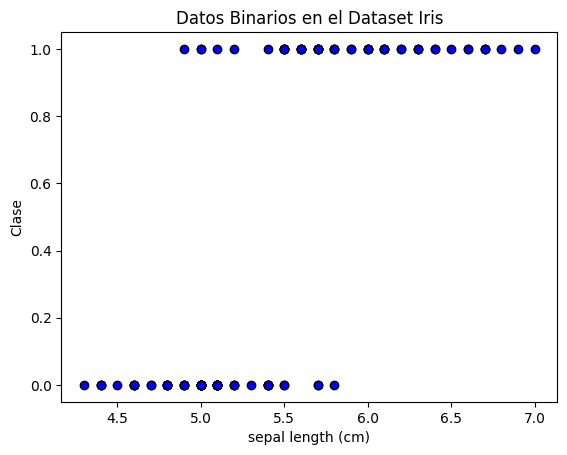

In [26]:
# Representamos los datos
plt.scatter(X, y, color='blue', edgecolor='k')
plt.xlabel(iris.feature_names[0])
plt.ylabel('Clase')
plt.title('Datos Binarios en el Dataset Iris')
plt.show()

In [41]:
#CARGAMOS LA LIBRERÍA PARA REGRESIÓN LOGÍSTICA
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

Más información sobre el algoritmo de Regresión Logística: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

In [44]:
# Entrenamos un modelo de regresión logística
model = LogisticRegression()
model.fit(X, y)

# Coeficientes de la solución
coef = model.coef_[0]
intercept = model.intercept_

# Imprimimos los coeficientes del modelo
print('Término independiente: beta_0:', intercept)
print('Coeficiente: beta_1:', coef)

Término independiente: beta_0: [-17.24560256]
Coeficiente: beta_1: [3.17578826]


In [43]:
# En el caso de que queramos hacer una Linear Regresion 
X_LR = pd.DataFrame(X)
Y_LR = pd.DataFrame(y)

X_train, X_test, y_train, y_test = train_test_split(X_LR, Y_LR, train_size= 0.2, random_state=0)

model = LinearRegression()
model.fit(X_train, y_train)

print(model.coef_)
print(model.intercept_)


y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print(f"El valor del MSE es {mse:.2f}%")

[[0.71026931]]
[-3.39937851]
El valor del MSE es 0.14%


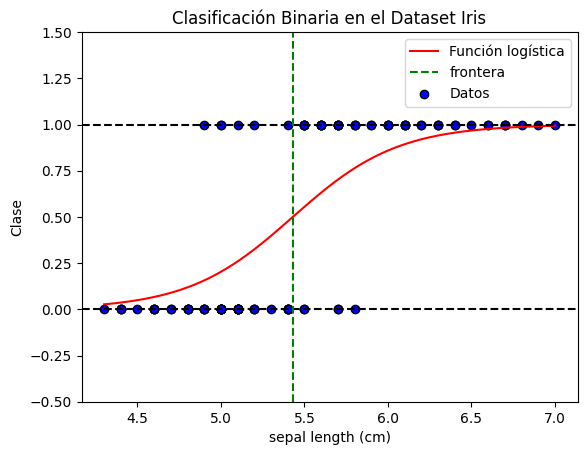

In [45]:
#REPRESENTAMOS LA FUNCIÓN LOGÍSTICA Y LA EC. DE FRONTERA

# Función logística (Para la exponencial usar np.exp)
def logistic_function(x):
    return 1 / (1 + np.exp(-x))

#Establecemos el dominio de x entre el máximo y el mínimo, utilizando mil puntos
x_values_logistic = np.linspace(np.min(X), np.max(X), 1000)
y_values_logistic = logistic_function(intercept + coef * x_values_logistic)
plt.plot(x_values_logistic, y_values_logistic, color='red', label='Función logística')
plt.xlabel('x')
plt.ylabel('y')
plt.ylim(-0.5, 1.5)

# Representamos los ejes y = 0 y y = 1
plt.axhline(y=0, color='black', linestyle='--')
plt.axhline(y=1, color='black', linestyle='--')

# Calculamos y marcar el punto donde la función logística vale 0.5 (Ecuación de frontera)
x_05 = -intercept / coef

#Representamos una línea vertical en la frontera
plt.axvline(x=x_05, color='green', linestyle='--', label='frontera')

#Volvemos a representar los datos:
plt.scatter(X, y, color='blue', edgecolor='k', label='Datos')
plt.xlabel(iris.feature_names[0])
plt.ylabel('Clase')
plt.title('Clasificación Binaria en el Dataset Iris')
plt.legend()

plt.show()



# CLASIFICACIÓN BINARIA CON DOS DIMENSIONES

In [46]:
# Cargamos el conjunto de datos Iris
iris = load_iris()
X = iris.data[:, :2]  # Tomamos solo las primeras dos características
y = iris.target

# Creamos un filtro para quedarnos solo con dos clases (clasificación binaria)
filter = (y == 0) | (y == 1)
X = X[filter]
y = y[filter]

In [47]:
#Imprimimos la dimensión de X
X.shape

(100, 2)

In [48]:
#Imprimimos la dimensión de y
y.shape

(100,)

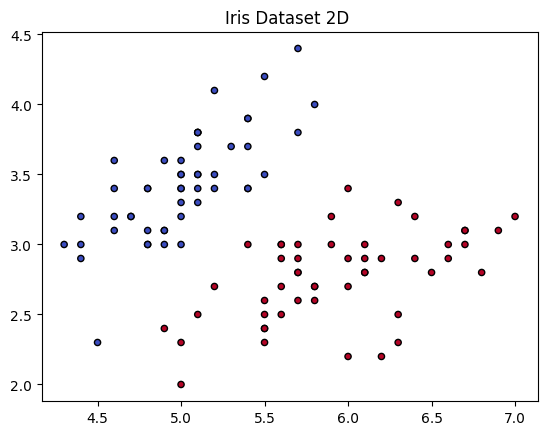

In [50]:
# Representamos los datos
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=20)
plt.title('Iris Dataset 2D ')

plt.show()

In [51]:
# Entrenamos un modelo de regresión logística
model = LogisticRegression()
model.fit(X, y)

# Coeficientes para la frontera de decisión
coef = model.coef_[0]
intercept = model.intercept_

# Imprimimos los coeficientes del modelo
print('Término independiente: beta_0:', intercept)
print('Coeficientes: beta_1, beta_2:', coef)

Término independiente: beta_0: [-7.33819169]
Coeficientes: beta_1, beta_2: [ 3.08267284 -3.01867739]


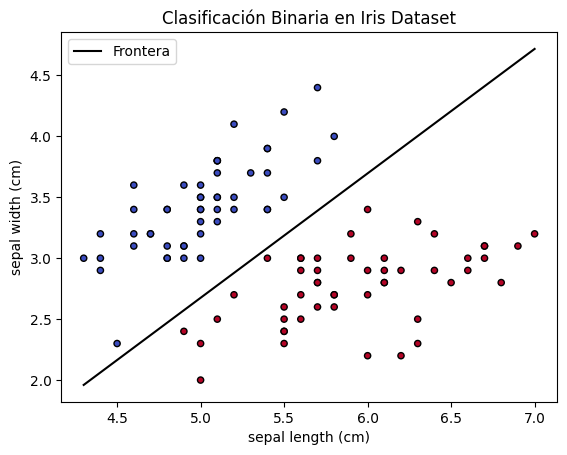

In [52]:
# REPRESENTAMOS LA ECUACIÓN DE FRONTERA JUNTO A LOS DATOS

# Sacamos los valores máximos y mínimos de la primera coordenada
# para determinar los extremos de la representación gráfica
x_values = np.array([np.min(X[:, 0]), np.max(X[:, 0])])

#Representamos la frontera de decisión
y_values = -(coef[0]/coef[1]) * x_values - intercept/coef[1]
plt.plot(x_values, y_values, color='black', label='Frontera')

# Representamos los datos de nuevo
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=20)

plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title('Clasificación Binaria en Iris Dataset')
plt.legend()

plt.show()

# CLASIFICACIÓN CON TRES CLASES EN DOS DIMENSIONES

In [53]:
# Cargar el conjunto de datos Iris
iris = load_iris()
X = iris.data[:, :2]  # Tomamos solo las primeras dos características
y = iris.target

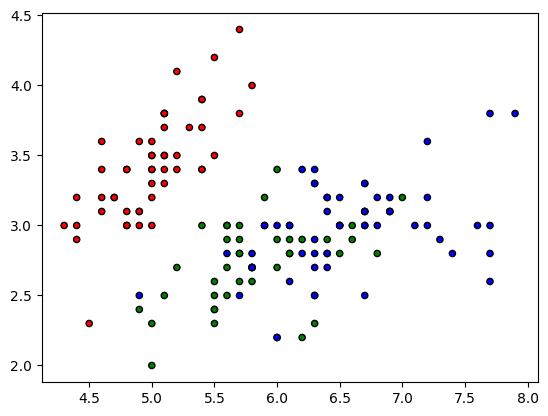

In [54]:
# Representamos  los datos
from matplotlib.colors import ListedColormap

#Colores para los datos
cmap_bold = ListedColormap(['red', 'green', 'blue'])

# Gráfico de dispersión
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold, edgecolor='k', s=20)

plt.show()

In [55]:
# Creamos el modelo de clasificación KNN
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)

# Entrenamos el modelo
knn.fit(X, y)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [27]:
# Creamos una malla de puntos para trazar la frontera de decisión
# Primero establecemos los límites
x_min = X[:, 0].min() - 1
x_max = X[:, 0].max() + 1

y_min = X[:, 1].min() - 1
y_max = X[:, 1].max() + 1

# Creamos una malla de puntos bidimensional entre los límites con espaciado 0.1
# entre los puntos
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                     np.linspace(y_min, y_max, 100))

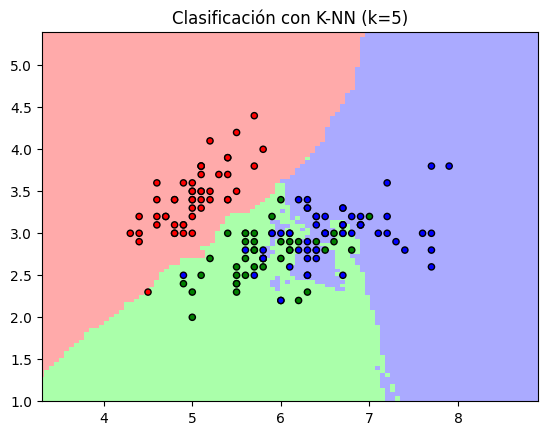

In [28]:
# Predecimos la clase para cada punto en la malla con el modelo entrenado
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Colores para la gráfica
cmap_bold = ListedColormap(['red', 'green', 'blue'])
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])

# Representar la frontera de decisión
plt.figure()
plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

# Representar también los datos de nuevo
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold, edgecolor='k', s=20)

#Límites de la gráfica
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.title("Clasificación con K-NN (k=5)")

plt.show()